# 2 · Modalite eşleştirme (Kriter 4)

**Soru:** Kamera, mikrofon, ortam sensörü ve etiket ayrı dosyalara, farklı hızlarda yazıyor. Aynı ana nasıl bağlanıyor ve
bağlantının doğru olduğunu nereden biliyoruz?

| Modalite | Ham hız | Izgaraya nasıl oturuyor |
|---|---|---|
| Etiket | 10 sn'de 1 satır | ızgaranın kendisi |
| Ortam | 10 sn'de 1 satır | aynı zaman → bire bir |
| Ses | dosya başına 10 sn | dosya başlangıcı → bire bir |
| Görüntü | saniyede 1 kare | 10 kareden pencerenin **ortasındaki** seçilir |

**Anahtar:** (ev, zaman). Excel'de iki tabloyu ortak sütundan birleştirmek gibi.

**Kurulum hücresi.** Önce bunu çalıştır (ya da Run → Run All). Kütüphaneleri, projenin `src/` kodlarını ve
etiketleri yükler; sonraki hücreler buradaki isimleri kullanır.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))           # projenin kendi kodları (src/) buradan çağrılır
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from build import OUT, INTERIM, ENV_COLS, HOMES, hubs_of
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CLS = ["0 kişi", "1 kişi", "2+ kişi"]; RENK = ["#2A78D6", "#EB6834", "#1BAF7A"]   # bütün grafiklerde aynı renkler
LAB = {h: pd.read_parquet(OUT / h / "labels.parquet") for h in HOMES}           # etiketler (her ev için 10 sn ızgara)
print("evler:", HOMES, "| toplam pencere:", sum(map(len, LAB.values())))

evler: ['H1', 'H2', 'H3', 'H4', 'H5', 'H6'] | toplam pencere: 1311925


## 2.1 Zamanı ızgaraya oturtmak

`build.grid_index`: her zaman damgasını 10 saniyeye aşağı yuvarlar (*floor*) ve ızgarada kaçıncı satır olduğunu bulur.
Izgarada olmayan zaman `-1` döner (etiketsiz gün = düşen kayıt).

In [2]:
from build import grid_index
row_of = grid_index(LAB["H1"])
zamanlar = ["2019-11-26 17:00:00", "2019-11-26 17:00:03", "2019-11-26 17:00:09", "2019-11-26 17:00:10", "2019-12-31 12:00:00"]
pd.DataFrame({"zaman": zamanlar, "pencere başı (floor 10s)": pd.DatetimeIndex(zamanlar).floor("10s"),
              "satır": row_of(zamanlar)})

,zaman,pencere başı (floor 10s),satır
0,2019-11-26 17:00:00,2019-11-26 17:00:00,6120
1,2019-11-26 17:00:03,2019-11-26 17:00:00,6120
2,2019-11-26 17:00:09,2019-11-26 17:00:00,6120
3,2019-11-26 17:00:10,2019-11-26 17:00:10,6121
4,2019-12-31 12:00:00,2019-12-31 12:00:00,-1


17:00:00 ile 17:00:09 arasındaki her şey aynı satıra (aynı pencereye) düşüyor. 31 Aralık etiket kaydında yok → `-1`.

## 2.2 Görüntü: 10 kareden hangisi?

Bir pencerede kamera 10 kare çekiyor. Ardışık kareler neredeyse aynı; hepsini vermek modeli 10 kat ağırlaştırır.
Pencereyi en iyi temsil eden **ortadaki kare** (5. saniye) seçiliyor; o yoksa ortaya en yakın olan.

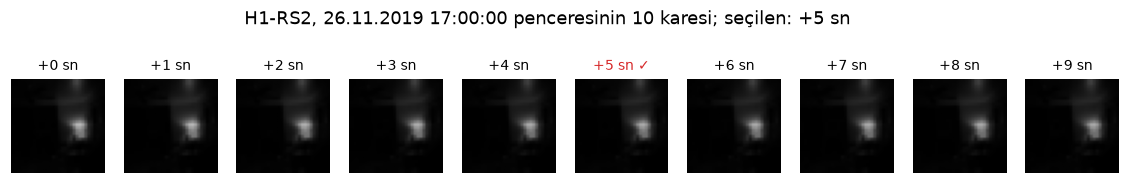

In [3]:
from PIL import Image
S = ROOT / "data" / "samples" / "H1" / "2019-11-26" / "1700"
fig, ax = plt.subplots(1, 10, figsize=(13, 1.8))
for k in range(10):
    f = S / f"2019-11-26_1700{k:02d}_RS2_H1.png"
    ax[k].imshow(np.asarray(Image.open(f).convert("L")), cmap="gray", vmin=0, vmax=255); ax[k].axis("off")
    ax[k].set_title(f"+{k} sn" + (" ✓" if k == 5 else ""), color="C3" if k == 5 else "k", fontsize=9)
fig.suptitle("H1-RS2, 26.11.2019 17:00:00 penceresinin 10 karesi; seçilen: +5 sn", y=1.08); plt.show()

In [4]:
# Bütün evlerde seçilen karenin pencere ortasına uzaklığı (offset = kaçıncı saniye; -1 = kare yok)
off = pd.concat([pd.read_parquet(OUT / h / f"{hub}_img.parquet")["offset"] for h in HOMES for hub in hubs_of(h)])
var = off[off >= 0]
print(f"karesi olan hub-pencere: {len(var):,} / {len(off):,}")
print("seçilen saniye dağılımı (%):"); print((var.value_counts(normalize=True).sort_index() * 100).round(2).to_string())

karesi olan hub-pencere: 3,901,461 / 6,084,425
seçilen saniye dağılımı (%):
offset
0     0.01
1     0.02
2     0.03
3     0.06
4     0.17
5    99.52
6     0.10
7     0.05
8     0.03
9     0.02


Karesi olan pencerelerin çok büyük kısmında tam 5. saniyedeki kare seçilmiş. Kayma en fazla birkaç saniye; 10 saniyelik
pencere içinde kaldığı için etiketle uyum bozulmuyor.

## 2.3 Eşleşme oranları (hub bazında)

`stats.json`'dan: ortamda eşleşen satır, seste eşleşen dosya, görüntüde karesi olan pencere.

In [5]:
R = []
for h in HOMES:
    st = json.loads((OUT / h / "stats.json").read_text()); n = st["labels"]["rows"]
    for hub in hubs_of(h):
        e, a, i = st[f"{hub}/env"], st[f"{hub}/aud"], st[f"{hub}/img"]
        R.append({"ev-hub": f"{h}-{hub}", "ortam eşleşen %": 100 * e["matched"] / n,
                  "ses dosyası eşleşen %": 100 * a["matched"] / max(a["files"], 1),
                  "sesi olan pencere %": 100 * a["matched"] / n,
                  "karesi olan pencere %": 100 * i["windows_with_img"] / n})
R = pd.DataFrame(R).set_index("ev-hub").round(1)
display(R.describe().loc[["mean", "min", "max"]].round(1)); R

,ortam eşleşen %,ses dosyası eşleşen %,sesi olan pencere %,karesi olan pencere %
mean,94.2,96.3,87.4,65.6
min,21.9,0.0,0.0,45.8
max,98.9,100.0,97.4,100.0


,ortam eşleşen %,ses dosyası eşleşen %,sesi olan pencere %,karesi olan pencere %
ev-hub,,,,
H1-RS1,97.5,99.5,94.2,54.8
H1-RS2,98.9,99.5,96.7,99.4
H1-RS3,97.6,99.5,94.5,55.6
H1-RS4,97.9,99.5,95.5,51.5
H1-RS5,98.0,99.5,95.7,45.8
H2-RS1,97.4,100.0,90.3,69.6
H2-RS2,95.7,100.0,89.3,76.4
H2-RS4,96.3,100.0,91.6,100.0
H2-RS5,98.1,100.0,91.8,76.8


**Okuma:** "Ses dosyası eşleşen %" neredeyse her yerde ~100: var olan dosyalar doğru pencereye oturuyor. "Sesi olan
pencere %" ise bazı hub'larda düşük (ör. H6-BS2 = 0): orada mikrofon hiç kayıt yapmamış; bu eşleştirme hatası değil, **eksik
modalite**. "Karesi olan pencere %" düşüklüğü gece karanlık karelerden (Notebook 4 ve 7).

## 2.4 Ham dosya = işlenmiş satır (birebir kontrol)

Bir pencereyi ham dosyalardan ve işlenmiş diziden ayrı ayrı okuyup karşılaştırıyoruz. `assert` = "eşit değilse hata ver".

In [6]:
S = ROOT / "data" / "samples" / "H1"
raw_img = np.asarray(Image.open(S / "2019-11-26/1700/2019-11-26_170005_RS2_H1.png").convert("L"))
raw_aud = np.loadtxt(S / "H1_RS2_AUDIO/2019-11-26/1700/2019-11-26_170000_RS2_H1.csv")
raw_env = pd.read_csv(INTERIM / "H1/H1_RS2_ENV/2019-11-26_RS2_H1_env.csv", index_col=0, parse_dates=True).loc["2019-11-26 17:00:00", ENV_COLS]
i = int(np.flatnonzero(LAB["H1"]["ts"] == "2019-11-26 17:00:00")[0])
assert (np.load(OUT / "H1/RS2_img.npy", mmap_mode="r")[i] == raw_img).all()                       # kare aynı
assert np.allclose(np.load(OUT / "H1/RS2_aud.npy", mmap_mode="r")[i].astype(float), np.log1p(raw_aud), rtol=1e-3)  # ses = log(1+ham)
assert np.allclose(np.load(OUT / "H1/RS2_env.npy")[i], raw_env.to_numpy(), equal_nan=True)          # ortam aynı
print(f"satır {i}: kare, ses ve ortam ham dosyalarla birebir aynı ✓")

satır 6120: kare, ses ve ortam ham dosyalarla birebir aynı ✓


## 2.5 Bağımsız kanıt: kamera ile ışık sensörü aynı anda değişiyor mu?

Kamera ve ışık sensörü **iki ayrı cihaz**. Eşleştirme doğruysa ışık yanınca karenin parlaklığı da aynı pencerede artmalı.
Saatler birkaç dakika kaysaydı bu uyum bozulurdu. Ölçü: **Spearman ρ** (sıra korelasyonu; −1 ile 1 arası, 1 = tam uyum).
Hız için her hub'dan her 30. pencere (5 dakikada bir) alınıyor.

In [7]:
L = ENV_COLS.index("light_lux"); rho = {}
for h in HOMES:
    for hub in hubs_of(h):
        ok = pd.read_parquet(OUT / h / f"{hub}_img.parquet")["offset"].to_numpy() >= 0
        idx = np.flatnonzero(ok)[::30]
        br = np.load(OUT / h / f"{hub}_img.npy", mmap_mode="r")[idx].mean(axis=(1, 2))
        lux = np.load(OUT / h / f"{hub}_env.npy")[idx, L]
        rho[f"{h}-{hub}"] = pd.Series(br).corr(pd.Series(lux), method="spearman")
rho = pd.Series(rho).round(2)
print(f"medyan ρ = {rho.median():.2f}, en yüksek {rho.max():.2f}; ρ < 0,3 olan hub'lar:", rho[rho < 0.3].to_dict())

medyan ρ = 0.84, en yüksek 0.98; ρ < 0,3 olan hub'lar: {'H2-RS4': 0.15, 'H3-RS1': 0.25, 'H5-RS3': 0.17, 'H6-BS5': 0.02}


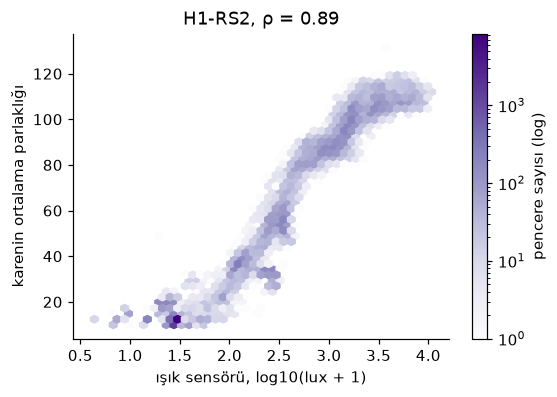

In [8]:
ok = pd.read_parquet(OUT / "H1/RS2_img.parquet")["offset"].to_numpy() >= 0
idx = np.flatnonzero(ok)[::10]
br = np.load(OUT / "H1/RS2_img.npy", mmap_mode="r")[idx].mean(axis=(1, 2)); lux = np.load(OUT / "H1/RS2_env.npy")[idx, L]
plt.figure(figsize=(5.5, 3.6)); plt.hexbin(np.log10(lux + 1), br, gridsize=45, bins="log", cmap="Purples")
plt.xlabel("ışık sensörü, log10(lux + 1)"); plt.ylabel("karenin ortalama parlaklığı"); plt.title(f"H1-RS2, ρ = {rho['H1-RS2']}")
plt.colorbar(label="pencere sayısı (log)"); plt.show()

**Yorum:** Koyu bant sol alttan sağ üste çıkıyor: ışık arttıkça kare parlıyor. Hub'ların medyan uyumu yüksek; bu,
eşleştirmenin doğru olduğunun modelden bağımsız kanıtı. Uyumun düşük olduğu birkaç hub (ör. H6-BS5) eşleştirme hatası
değil; kameranın otomatik pozlaması yüzünden (Notebook 4'te ayrıntılı vaka).